<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    LNDb - Lung Nodule Database
  </h1>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    A datased based on LIDC-IDRI
  </h3>

  <p>
   The LNDb was developed as an external dataset complimentary to LIDC-IDRI. There are a few important differences between the two... While LIDC-IDRI is a project shared between 7 institutions, LNDb is a smaller dataset, belonging to a single institution - Centro Hospitalar e Universitário de São João (CHUSJ) in Porto.
  </p>
  <p>
   LNDb contains 294 CT scans - about a quarter of the size of LIDC-IDRI, and its classification method is different as well: it uses a single-blind methodology (a radiologist would read the scan once and no consensus or review between the radiologists was performed), instead of having multiple radiologists reading the same scan. This might cause a noticeable distinction in classification pattern for each radiologist; but, unlike LIDC-IDRI, the 5 participant radiologists are identified uniformly throughout the dataset as R1, R2, R3, R4 and R5.
  </p>
  <p>
   The variability in acquisition parameters is significantly lower in LNDb, as well as the subjective characterization of nodules. LNDb is overall a more clinically realistic dataset.
   </p>
  
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Initial Data Analysis
  </h3>

  <p>
    To access LNDb's auxiliary functions, which will help us to visualize, understand and manipulate data, we must import the script <strong>'utils.py'</strong> and other scripts made available with the download of the dataset.
  </p>
  <p>
    The first step in our analysis of the dataset is to ensure that we can read the MetaImage <strong>.mhd/.raw</strong> medical image files - both the Computerized Tomography (CT) data and the segmentation masks are in this format. The file <strong>'utils.py'</strong> includes routines based on the SimpleITK library that allow us to... 
  </p>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Load the 3D CT images and the nodule masks.</li>
    <li style="margin-bottom: 8px;">Extract the metadata from the medical images, such as the pixel/voxel spacing, the origin and the orientation matrix of the CT.</li>
  </ol>
  <p>
    We also want to match scan slices to nodule coordinates. Thus, we have created a reusable function <strong>read_nods_in_scan</strong> which, for one scan metadata file LNDb-XXXX.mhd, and its corresponding image LNDb-XXXX.raw, extracts the necessary information for coordinate conversion from milimeters into pixels/voxels and vice-versa. This is possible using the origin, the spacing and transformation matrix of the scan. 
  </p>
  <p>
    This function also reads the nodule coordinates from <strong>'trainNodules.csv'</strong>, in milimeters, and converts them to image coordinates, in pixel / cut indexes, using the origin and transformation origin of the corresponding scan. This way, we can associate these coordinates with the scan image. This way, we are able to quickly visualize every node in each CT Scan!
  </p>
</div>

In [ ]:
import os, sys
sys.path.append(os.path.abspath('..'))
from src.LNDb_utils import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def read_nods_in_scan(LNDb_id, scan_folder, nods_table): #Reads one CT Scan and returns array, metadata and scan nodules with converted coordinates.
    path_mhd = os.path.join(scan_folder, f'LNDb-{LNDb_id:04d}.mhd')
    scan, spacing, origin, transfmat = utils.readMhd(path_mhd) # read metadata from scan, necessary for coordinate conversion
    transfmat_toimg, transfmat_toworld = utils.getImgWorldTransfMats(spacing, transfmat) #
    nods_scan = nods_table[nods_table['LNDbID'] == LNDb_id].copy()

    coords_img = []
    for _, line in nods_scan.iterrows():
        xyz_world = np.array([line['x'], line['y'], line['z']])
        xyz_img = utils.convertToImgCoord(xyz_world, origin, transfmat_toimg)
        coords_img.append(xyz_img)

    nods_scan['x_img'] = [c[0] for c in coords_img]
    nods_scan['y_img'] = [c[1] for c in coords_img]
    nods_scan['z_img'] = [c[2] for c in coords_img]

    return scan, spacing, origin, nods_scan

ct_scan_id = 1
nods_table = pd.read_csv('../data/LNDb/train/trainset_csv/trainNodules.csv')
scan, spacing, origin, nods_scan = read_nods_in_scan(ct_scan_id, '../data/LNDb/train/ct_scans', nods_table)

print(f"The CT Scan {ct_scan_id} has...\n  -> dimensions {scan.shape}\n  -> origin {origin}\n  -> spacing {spacing}\n")
print(f"For this scan, we have {len(nods_scan)} findings:")
print(nods_scan[['LNDbID', 'RadID', 'FindingID', 'x_img', 'y_img', 'z_img']])

The CT Scan 1 has...
  -> dimensions (328, 512, 512)
  -> origin (-158.1962890625, -309.1962890625, -297.5)
  -> spacing (0.607421875, 0.607421875, 1.0)

For this scan, we have 4 nodules:
   LNDbID  RadID  FindingID  x_img  y_img  z_img
0       1      1          1  187.0  313.0  260.0
1       1      1          2  303.0  300.0  252.0
2       1      2          1  188.0  314.0  260.0
3       1      3          1  188.0  312.0  260.0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By the shape of the scan array, we can conclude that it has 328 cuts of 512x512 pixels. The voxel spacing (0.607, 0.607, 1.0)mm shows that the volume <strong>is not isotropic</strong> because the plane resolution is thinner than in between cuts. This is something to have in mind if we decide to resample into a uniform spacing before feature extraction - this probably makes the most sense. 
  </p>
  <div style="background-color: #c25719; padding: 2px 10px; border-radius: 0px; margin: 0px -10px;">
    <strong style="color: #1967d2;">Note:</strong> An isotropic volume implies that the spacing between voxels is equal in all directions (x, y, z) - in other words, each voxel is shaped like a perfect cube.
  </div>
  <p>
    Lastly, the origin indicates the coordinate of the word corresponding to the volume corner, necessary to convert nodule coordinates in further steps.
  </p>
  <p>
    Now, we must confirm visually the coordinate conversion by showing the exact cut where the nodule was annotated, with a red <strong>X</strong> in its position. Below, there is the side-by-side comparison of the original image and the annotated image with its nodules.
  </p>
</div>

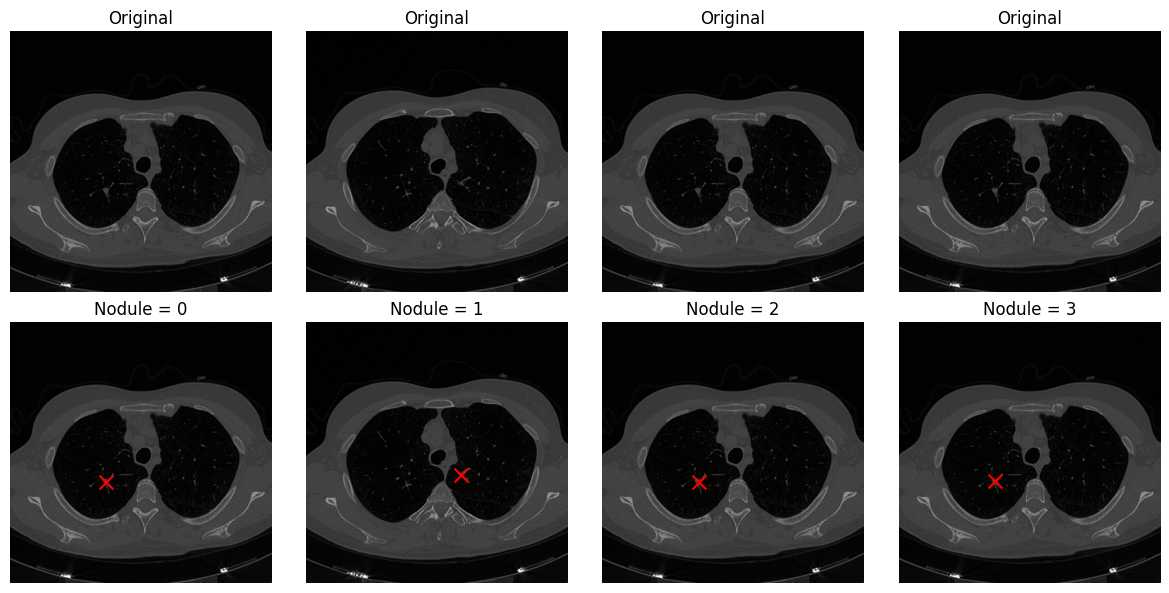

In [43]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(len(nods_scan)):
    axes[0][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[0][i].set_title(f"Original")
    axes[0][i].axis("off")  # Hides x and y tick marks
    axes[1][i].imshow(scan[int(nods_scan['z_img'].iloc[i])], cmap='gray')
    axes[1][i].set_title(f"Nodule = {i}")
    axes[1][i].scatter(nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], c='red', marker='x', s=100)  # marca a posição do nódulo
    axes[1][i].axis("off")
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    By comparing the original CT slice with the annotated nodule, we confirm that it does, indeed, correspond to the location of a nodule. However, for this CT Scan, we also understand that nodules 0, 2 and 3 are the same - they were simply marked by 3 different radiologists. This can be confirmed both by their 'FindingID' and by taking a closer look at the nodules. The <strong>'utils.py'</strong> module has a function which extracts a small region of an image (typically 80x80x80 voxels) surrounding a central point. This makes it very easy to get a centered image of each nodule!
  </p>
</div>

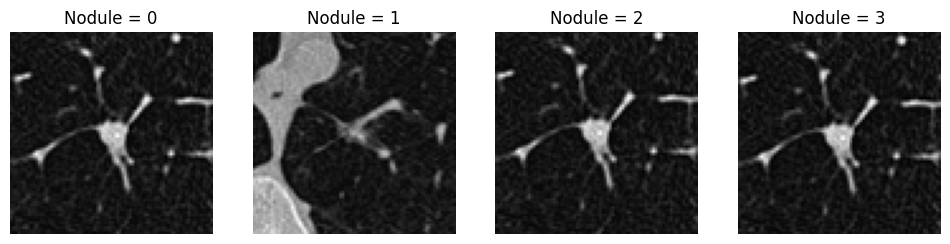

In [42]:
fig, axes = plt.subplots(1, 4, figsize=(12, 6))
for i in range(len(nods_scan)):
    cube = utils.extractCube(scan, spacing, (nods_scan['x_img'].iloc[i], nods_scan['y_img'].iloc[i], nods_scan['z_img'].iloc[i]))
    axes[i].imshow(cube[cube.shape[0]//2], cmap='gray')
    axes[i].set_title(f"Nodule = {i}")
    axes[i].axis("off")  # Hides x and y tick marks
plt.show() 
# Adjust spacing and display

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    And, as it is very clear now, there are 3 repeated nodules. This repetitions happens because the file <strong>'trainNodules.csv'</strong> has an entry for each finding made by a radiologist. So, if many radiologists annotate the same nodule, there are many rows corresponding to that node in the file. 
  </p>
  <p>
    This also happens in another file available in our dataset: <strong>chars_trainNodules.csv</strong>. In fact, these two complement eachother! The first stores the (x, y, z) coordinates of each finding, the nodule classification (nodule / non-nodule) and the volume and texture (necessary for calculating Fleischner Score). The second stores the subjective characteristics of each nodule (calcification, internal structure, malignancy, ...). So, it is a good idea to join them in one single file.
  </p>
  <p>
    However, there is a small detail to take into account - there is disparity line-wise in these files. <strong> chars_trainNodules.csv</strong> contains records from all 5 radiologists, while <strong>trainNodules.csv</strong> only contains records from radiologists 1, 2 and 3. This happens because not all radiologists annotated the coordinates of their findings, and in some situations they have also not annotated the characteristics, resulting in some lines not being common to both files. This can be handled with an outer junction, which does not eliminate any information, but joins lines that appear in both tables.
  </p>
</div>

In [51]:

char_train= pd.read_csv('../data/LNDb/train/trainset_csv/chars_trainNodules.csv')
train = pd.read_csv('../data/LNDb/train/trainset_csv/trainNodules.csv')
train = train.astype('float64')

# 'outer' keeps all entries, 'inner' keeps only nodules present in both.
combined_df = pd.merge(train, char_train, on=['LNDbID', 'RadID', 'FindingID'], how="outer")

print(combined_df.shape)
combined_df.head()

(2384, 17)


,LNDbID,RadID,FindingID,x,y,z,Nodule,Volume,Text,calcification,internalStructure,lobulation,malignancy,margin,sphericity,spiculation,subtlety
0,1.0,1.0,1.0,-44.608398,-119.073242,-37.5,1.0,440.908794,5.0,6.0,1.0,1.0,2.0,4.0,2.0,2.0,5.0
1,1.0,1.0,2.0,25.852539,-126.969727,-45.5,1.0,152.381031,4.0,6.0,1.0,1.0,2.0,4.0,2.0,1.0,3.0
2,1.0,2.0,1.0,-44.000977,-118.465820,-37.5,1.0,56.820045,5.0,3.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0
3,1.0,3.0,1.0,-44.000977,-119.680664,-37.5,1.0,169.353252,5.0,5.0,1.0,2.0,2.0,3.0,4.0,3.0,4.0
4,2.0,1.0,1.0,88.895508,-123.625977,-129.5,1.0,339.187950,5.0,6.0,1.0,1.0,1.0,5.0,3.0,1.0,5.0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    Now, let us take a moment to understand the meaning of each column in our dataframe. We must have a clear understanding of our data so that we can make better processing choices and achieve better accuracy on our final predictions.
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">Each line corresponds to a finding <strong>'FindingID'</strong> marked by a radiologist <strong>'RadID'</strong> in a scan <strong>'LNDbID'</strong>.</li>
    <li style="margin-bottom: 8px;">Includes the column <strong style="color: #c25719;">'malignancy'</strong>, which categorizes on a scale from 1 to 5 the overall probability assessment that the nodule is cancerous based on its size, growth rate, and combination of physical features. There are also other important characteristics regarding the physical aspect of the nodule, which contribute for the characterization of malignancy:
      <ol style="padding-left: 30px; margin-bottom: 0px;">
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Calcification</strong> refers to calcium deposits inside the nodule, which appear bright white on CT. When a nodule is benign, it is common to observe central, diffuse, laminated (concentric rings), or "popcorn" calcifications, which usually indicate past infections, granulomas, or hamartomas. However, if the calcification is eccentric (off-center) or stippled (tiny scattered specks), it can more frequently be linked to malignancy.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Internal Structure</strong> describes what the inside of the nodule consists of; specifically, its tissue density and components. If <strong>solid</strong>, it is dense throughout, completely obscuring lung tissue behind it. If <strong>subsolid / ground-glass (GGO)</strong>, it is a hazy area where underlying blood vessels and lung structures remain visible. If <strong>part-solid</strong>, it contains both solid and ground-glass areas. Finally, <strong>fat</strong> inside a nodule strongly favors a benign hamartoma, while thick-walled hollow centers - <strong>cavitation</strong> warrant careful evaluation.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Lobulation</strong> refers to an undulating, scalloped, or wave-like outer contour instead of a smooth circle. Lobulated margins occur due to uneven growth rates in different parts of the nodule and carry a moderate association with malignancy.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Margin</strong> is the general appearance of the border where the nodule meets normal lung tissue. If <strong>smooth / well-defined</strong>, it is typically a reassuring sign. If <strong>ill-defined / irregular</strong>, then it points towards malignancy.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Sphericity</strong> measures how closely the nodule resembles a 3D sphere versus an elongated or flat shape. Perfectly round nodules are less common, but highly irregular or asymmetric 3D shapes can reflect invasive growth.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Spiculation</strong> refers to strands or "spikes" radiating outward from the edge of the nodule into surrounding lung tissue, giving it a sunburst or starburst appearance. This is one of the strongest radiological signs associated with malignancy.</li>
        <li style="margin-bottom: 0px;"><strong style="color: #c25719;">Subtlety</strong> indicates how easy or difficult the nodule is to visually distinguish from surrounding structures (like normal blood vessels, chest wall, or diaphragm). High subtlety means it is faint or hidden, while low subtlety means it stands out starkly.</li>
      </ol>
    </li>
    <li style="margin-bottom: 8px;">There are no (x, y, z) coordinates. To obtain them, we must connect this file to <strong>'trainNodules.csv'</strong>.</li>
  </ul>

  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
    Visualizing and locating a nodule in a scan
  </h3>

</div>

## Inventariar os scans disponíveis

Como ainda só tenho o `data0.rar` descarregado comecei por identificar quais LNDbID têm mesmo o .mhd correspondente na pasta local, para não tentarmos processar scans que ainda não temos

In [ ]:
# descobrir que LNDbIDs existem realmente na pasta descarregada
ficheiros_mhd = [f for f in os.listdir(r'C:\LNDb_data0') if f.endswith('.mhd')]
ids_disponiveis = sorted([int(f.replace('LNDb-', '').replace('.mhd', '')) for f in ficheiros_mhd])
print(f'{len(ids_disponiveis)} scans disponíveis: {ids_disponiveis[:10]}...')

43 scans disponíveis: [1, 2, 3, 4, 5, 7, 8, 10, 11, 13]...


**Conclusão:** há `43` scans disponíveis localmente, de um total de `294` no LNDb completo (~15%). É suficiente para validar o pipeline, mas a tabela final ainda está incompleta

## Aplicar a todos os scans disponíveis



In [ ]:
todas_as_tabelas = []

for lndb_id in ids_disponiveis:
    try:
        _, _, _, nods = ler_scan_e_nodulos(lndb_id, r'C:\LNDb_data0', merged)
        todas_as_tabelas.append(nods)
    except Exception as e:
        print(f'Erro no LNDbID {lndb_id}: {e}')

tabela_final = pd.concat(todas_as_tabelas, ignore_index=True)
print(tabela_final.shape)

(377, 20)


**Conclusão:** obtivemos 377 linhas de nódulos a partir dos 43 scans (uma média de ~8,8 observações por scan, contando cada radiólogo separadamente)

## Exportar no esquema combinado com o grupo

Verificar se mantemos ou alteramos o esquema da tabela

In [ ]:
tabela_gerada = pd.DataFrame({
    'dataset': 'LNDb',
    'scan_id': tabela_final['LNDbID'],
    'nodulo_id': tabela_final['FindingID'],
    'x': tabela_final['x_img'],
    'y': tabela_final['y_img'],
    'z': tabela_final['z_img'],
    'diametro_mm': None,  # LNDb dá volume, não diâmetro direto — ver nota abaixo
    'categoria': tabela_final['Nodule'],
    'malignidade_rating': tabela_final.get('malignancy'),  # confirmem o nome exato da coluna
    'radiologo_id': tabela_final['RadID'],
})

tabela_gerada.to_csv('lndb_processado.csv', index=False)
print('Guardado com sucesso:', tabela_gerada.shape)

Guardado com sucesso: (377, 10)


## Calcular o diâmetro equivalente a partir do volume

O LNDb não dá o diâmetro do nódulo diretamente, apenas o volume. Podemos usar a função nodEqDiam (fornecida no `readNoduleList.py`), que assume o nódulo como uma esfera e calcula o diâmetro equivalente a partir do volume:

**Diâmetro equivalente:**
$$d = 2 \left( \frac{3V}{4\pi} \right)^{1/3}$$

onde V representa o volume do nódulo em mm³, tal como vem no CSV.

In [ ]:
from readNoduleList import nodEqDiam
tabela_gerada['diametro_mm'] = tabela_final['Volume'].apply(nodEqDiam)

Voltar a guardar o csv